<a href="https://colab.research.google.com/github/GLzanetti/Projetos-de-Machine-Learning/blob/main/Aula4_MachineLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Aula 4 - Machine Learning - Previsão de numeros.

## Classificação de Dígitos Manuscritos com o Dataset MNIST

O dataset **MNIST** (Modified National Institute of Standards and Technology) é um dos conjuntos de dados mais clássicos e amplamente utilizados na área de aprendizado de máquina e visão computacional. Ele consiste em uma coleção de 70.000 imagens em tons de cinza de dígitos manuscritos de 0 a 9, cada uma com dimensões de 28x28 pixels. Este projeto aborda o desenvolvimento e comparação de modelos clássicos de aprendizado supervisionado para classificar corretamente estes dígitos.

### 📋 Objetivos do Projeto
O principal objetivo deste estudo é analisar e comparar o desempenho de três algoritmos supervisionados de Machine Learning na tarefa de classificação multiclasse:
* **Regressão Logística**: Um modelo linear clássico que serve como uma excelente linha de base (baseline).
* **Árvore de Decisão**: Um modelo não linear baseado em regras de decisão simples, de fácil interpretação.
* **Floresta Aleatória (Random Forest)**: Um método de ensemble que combina múltiplas árvores de decisão para melhorar a robustez e generalização.

Os modelos são avaliados com base na acurácia obtida nos conjuntos de treino e teste, no tempo de treinamento requerido e na capacidade de generalização (evitando o sobreajuste/overfitting).

### 🛠️ Detalhes da Implementação
Para viabilizar a execução eficiente dos modelos, as seguintes etapas de pré-processamento e engenharia de recursos foram executadas:
1. **Redução de Dimensionalidade (Amostragem)**: Redução do conjunto original para acelerar o aprendizado, utilizando as primeiras 20.000 amostras para treinamento e 3.000 amostras para teste.
2. **Achatamento (Flattening)**: Conversão das imagens bidimensionais de formato `28x28` pixels em vetores unidimensionais de `784` atributos (features) lineares.
3. **Normalização de Escala (MinMax Scaling)**: Divisão dos valores dos pixels (originalmente de 0 a 255) por 255.0. Isso escala todos os valores dos atributos para o intervalo numérico fechado de `[0, 1]`, o que otimiza de forma significativa a convergência e desempenho dos algoritmos de classificação.

Formato Original
Treino:  (60000, 28, 28) (60000,)
Teste:  (10000, 28, 28) (10000,)
Formato reduzido
Treino:  (20000, 28, 28) (20000,)
Teste:  (3000, 28, 28) (3000,)
Rotulo Verdadeiro:  5
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  4  4  6  0  5  9  8  4  0  0  0  0
  0  0  0  0  0  0  0  0  1  1  3  5  6  8  8  8  8  8  7  6  8  8  6  2  0  0  0  0
  0  0  0  0  0  0  0  1  8  8  8  8  8  8  8  8  8  8  3  2  2  1  1  0  0  0  0  0
  0  0  0  0  0  0  0  0  7  8  8  8  8  8  6  6  8  8  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  2  5  3  8  8  7  0  

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Acuracia Treino: 95.34%
Acuracia Teste: 89.40%
Tempo de Treinamento: 48.93 segundos
Quantidade de Erro: 318
Diferenca Treino e teste: 5.94
Treinando o modelo Arvore de Decisao
Acuracia Treino: 99.13%
Acuracia Teste: 81.97%
Tempo de Treinamento: 8.86 segundos
Quantidade de Erro: 541
Diferenca Treino e teste: 17.16
Treinando o modelo Floresta Aleatoria
Acuracia Treino: 99.87%
Acuracia Teste: 93.90%
Tempo de Treinamento: 19.16 segundos
Quantidade de Erro: 183
Diferenca Treino e teste: 5.97


,Modelo,Tempo Treinamento,Acuracia Treino,Acuracia Teste,Diferenca,Quantidade Erro
0,Regressao Logistica,48.93,0.95,0.89,0.06,318
1,Arvore de Decisao,8.86,0.99,0.82,0.17,541
2,Floresta Aleatoria,19.16,1.00,0.94,0.06,183


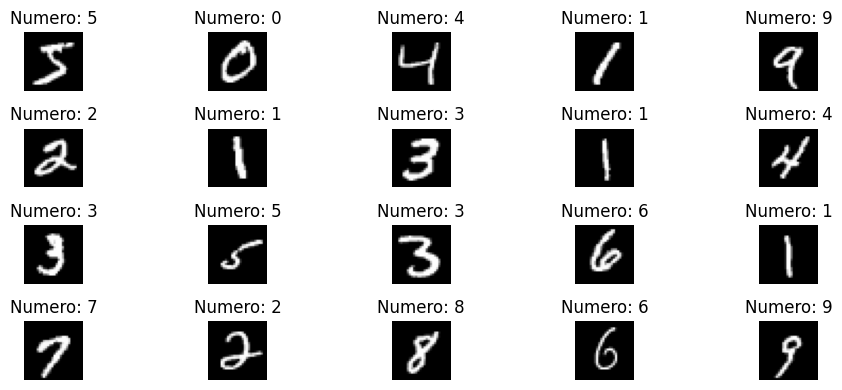

In [ ]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from google.colab import files
import cv2

from tensorflow.keras.datasets import mnist

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (accuracy_score, ConfusionMatrixDisplay, classification_report)

#1.0 Carregar o mist

(xTreino, yTreino), (xTeste, yTeste) = mnist.load_data()
print("Formato Original")
print("Treino: ", xTreino.shape, yTreino.shape)
print("Teste: ", xTeste.shape, yTeste.shape)

#2.0 Redução de dimensionalidade

xTreino = xTreino[:20000]
yTreino = yTreino[:20000]
xTeste = xTeste[:3000]
yTeste = yTeste[:3000]

print("Formato reduzido")
print("Treino: ", xTreino.shape, yTreino.shape)
print("Teste: ", xTeste.shape, yTeste.shape)

#3.0 Projetar alguns dados

plt.figure(figsize=(10,4))

for i in range(20):
  plt.subplot(4, 5, i+1)
  plt.imshow(xTreino[i], cmap="gray")
  plt.title(f"Numero: {yTreino[i]}")
  plt.axis("off")

plt.tight_layout()
#plt.show()

#4 Preparação dos dados

xTreino = xTreino.reshape(len(xTreino), 784)
xTeste = xTeste.reshape(len(xTeste), 784)

xTreino = xTreino/255
xTeste = xTeste/255

indice = 0
imagem = xTreino[indice].reshape(28, 28)
print("Rotulo Verdadeiro: ", yTreino[indice])

for linha in imagem:
  print("".join(f"{int(valor*9):3}" for valor in linha))

linear = LogisticRegression(max_iter=200)
arvore = DecisionTreeClassifier(max_depth=15, random_state=42)
floresta = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)

modelos = {
    "Regressao Logistica": linear,
    "Arvore de Decisao": arvore,
    "Floresta Aleatoria": floresta
}

#5 Resultados e metricas

resultados = []
previsoes = {}

for nome, modelo in modelos.items():
  print("=============================")
  print(f"Treinando o modelo {nome}")
  print("=============================")
  inicio = time.time()
  modelo.fit(xTreino, yTreino) #Erra, ve o que errou, ajusta
  fim = time.time()
  tempoTreinamento = fim - inicio

  yPrevisto = modelo.predict(xTeste) #Erra | Acerta
  previsoes[nome] = yPrevisto
  accTreino = modelo.score(xTreino, yTreino)
  accTeste = accuracy_score(yTeste, yPrevisto)

  print(f"Acuracia Treino: {accTreino*100:.2f}%")
  print(f"Acuracia Teste: {accTeste*100:.2f}%")

  diferenca = accTreino - accTeste
  quantidadeErro = sum(yPrevisto != yTeste)

  print(f"Tempo de Treinamento: {tempoTreinamento:.2f} segundos")
  print(f"Quantidade de Erro: {quantidadeErro}")
  print(f"Diferenca Treino e teste: {diferenca*100:.2f}")

  resultados.append({
      "Modelo": nome,
      "Tempo Treinamento": tempoTreinamento,
      "Acuracia Treino": accTreino,
      "Acuracia Teste": accTeste,
      "Diferenca": diferenca,
      "Quantidade Erro": quantidadeErro
  })

dfResultados = pd.DataFrame(resultados)
display(dfResultados.round(2))

Saving 4.png to 4 (2).png
4 (2).png


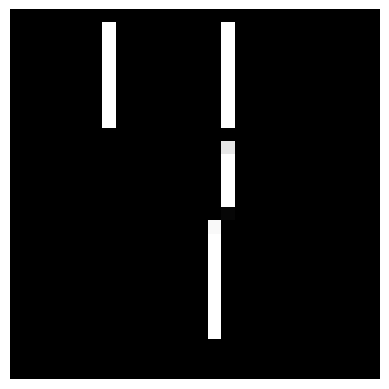

Regressao Logistica -> 3
Arvore de Decisao -> 9
Floresta Aleatoria -> 7


In [ ]:
arquivos = files.upload()
nome = list(arquivos.keys())[0]
print(nome)

img = cv2.imread(nome, 0)
img = cv2.resize(img, (28, 28))
img = cv2.bitwise_not(img)
img = img.reshape(1, 784) / 255.0

plt.imshow(img.reshape(28, 28), cmap="gray")
plt.axis("off")
plt.show()

for nome, modelo in modelos.items():
  print(nome, "->", modelo.predict(img)[0])